# Лабораторная №1 — Агент-художник

**Археология будущего: следы присутствия**

Команда: Аршинов Иван, Барулева Кристина, Губенков Илья, Якушина Анна.

Этот ноутбук содержит полный код агентного цикла и сохранённые результаты.
По умолчанию он **не делает новых платных API-запросов**: показывает выполненный
эксперимент из `data/` и `docs/assets/`. Чтобы повторить генерацию, измените
`RUN_GENERATION` ниже. Контрольные точки переиспользуются; для нового независимого
эксперимента сохраните результаты отдельно и выберите пустой каталог данных.

Перед первым запуском установите зависимости:
```python
%pip install -r requirements.txt
# Для дополнительного локального рендерера:
# %pip install -r requirements-openweight.txt
```
Скопируйте `.env.sample` в `.env` и заполните выданные преподавателем значения.
Не публикуйте этот файл. Подробности: `README.md`, `REPORT.md`, `MODEL_CARD.md`.


# Археология будущего
Лабораторная №1 «Агент-художник». Команда: Аршинов Иван, Барулева Кристина,
Губенков Илья, Якушина Анна.

Система разделяет замысел, визуальное исполнение и оценку: два независимых
LLM-агента общаются текстом, затем VLM-критик рассматривает реальную картину.
Все запросы, ответы, промпты, оценки и версии сохраняются на диск.

In [1]:
from __future__ import annotations

import argparse
import base64
import hashlib
import io
import json
import os
from pathlib import Path
import re
import time
from datetime import datetime, timezone
from typing import Any

from dotenv import load_dotenv
from openai import OpenAI
from PIL import Image

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
DATA = ROOT / 'data'
ASSETS = ROOT / 'docs' / 'assets'
TEAM = ['Аршинов Иван', 'Барулева Кристина', 'Губенков Илья', 'Якушина Анна']
SERIES = 'Археология будущего'
STYLE = (
    'A coherent series of conceptual fine-art paintings: a museum of intangible '
    'digital habits in the year 2126. Painterly material textures, oxidised copper, '
    'deep petrol and ultramarine, warm amber light, restrained ivory highlights. '
    'One legible metaphor per painting, generous negative space, visual hierarchy, '
    'quiet atmosphere. Not a literal computer illustration. No written words, '
    'no letters, no logos, no screens, no neon cyberpunk, no robots.'
)
BRIEFS = [
    {'id': '01-notification', 'title': 'Последнее уведомление',
     'question': 'Как выглядит потребность постоянно быть замеченным, когда отвечать уже некому?',
     'seed_idea': 'Археологический след уведомления: немой колокол и одно уцелевшее свечение.'},
    {'id': '02-unread', 'title': 'Сад непрочитанных сообщений',
     'question': 'Может ли невысказанное прорасти, если его так и не прочитали?',
     'seed_idea': 'Непрочитанные сообщения стали семенами; хрупкий сад хранит несовершившийся разговор.'},
    {'id': '03-cloud', 'title': 'Облачный гербарий',
     'question': 'Что остаётся от обещания хранить воспоминания вечно?',
     'seed_idea': 'Облачная память как гербарий: высушенные облака между музейными стёклами.'},
    {'id': '04-routes', 'title': 'Река отменённых маршрутов',
     'question': 'Где живут места, до которых мы решили не дойти?',
     'seed_idea': 'Несостоявшиеся маршруты собираются в русло, текущее через безлюдный музей.'},
]

def utcnow() -> str:
    return datetime.now(timezone.utc).isoformat()

def save_json(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')
    temporary.replace(path)

def read_json(path: Path) -> Any:
    return json.loads(path.read_text(encoding='utf-8'))

def extract_json(text: str) -> dict:
    """Allow Markdown fences, but reject missing/invalid JSON rather than inventing data."""
    start, end = text.find('{'), text.rfind('}')
    if start < 0 or end < start:
        raise ValueError('The agent did not return a JSON object.')
    # Some compatible backends emit literal tabs/newlines inside strings.
    # Accept these characters while retaining the exact raw response in the log.
    value = json.loads(text[start:end + 1], strict=False)
    if not isinstance(value, dict):
        raise ValueError('Expected a JSON object.')
    return value

## Настройка API и роли
`.env` размещается рядом с ноутбуком либо задаётся через `DOTENV_PATH`.
Значения не печатаются и не попадают в журнал. Responses API и Image Generation
API вызываются через совместимый клиент. История передаётся явно: это делает
независимые роли и контекст каждого решения видимыми и воспроизводимыми.

In [2]:
class Studio:
    def __init__(self) -> None:
        load_dotenv(Path(os.environ.get('DOTENV_PATH', ROOT / '.env')), override=False)
        self.folder = os.environ.get('folder_id') or os.environ.get('FOLDER_ID')
        self.key = os.environ.get('api_key') or os.environ.get('API_KEY')
        if not self.folder or not self.key:
            raise RuntimeError('Add folder_id and api_key to .env; see .env.sample.')
        self.models = {
            'curator': os.environ.get('CURATOR_MODEL', 'deepseek-v4.1-flash'),
            'artist': os.environ.get('ARTIST_MODEL', 'qwen3.6-35b-a3b/latest'),
            'critic': os.environ.get('CRITIC_MODEL', 'qwen3.6-35b-a3b/latest'),
            'image': os.environ.get('IMAGE_MODEL', 'aliceai-image-art-3.0/latest'),
        }
        self.client = OpenAI(base_url='https://ai.api.cloud.yandex.net/v1',
                             api_key=self.key, project=self.folder,
                             timeout=240, max_retries=2)

    def sanitize(self, value: Any) -> Any:
        if isinstance(value, str):
            return value.replace(self.key, '[API_KEY]').replace(self.folder, '[FOLDER_ID]')
        if isinstance(value, dict):
            return {key: self.sanitize(item) for key, item in value.items()}
        if isinstance(value, list):
            return [self.sanitize(item) for item in value]
        return value

    def ask(self, work: dict, role: str, stage: str, instructions: str,
            prompt: str, image: Path | None = None) -> dict:
        """Checkpoint every successful turn; a resumed run reuses it, not the API."""
        for event in work['dialogue']:
            if event['stage'] != stage:
                continue
            try:
                parsed = extract_json(event['output_text'])
                if role == 'critic':
                    parsed = validated_review(parsed)
            except (ValueError, json.JSONDecodeError):
                continue
            event['parsed'] = parsed
            checkpoint(work)
            return parsed
        model = self.models[role]
        content = [{'type': 'input_text', 'text': prompt}]
        if image:
            with Image.open(image) as source:
                source = source.convert('RGB')
                source.thumbnail((1024, 1024))
                buffer = io.BytesIO()
                source.save(buffer, format='JPEG', quality=90)
            encoded = base64.b64encode(buffer.getvalue()).decode('ascii')
            content.append({'type': 'input_image',
                            'image_url': f'data:image/jpeg;base64,{encoded}', 'detail': 'auto'})
        started = time.monotonic()
        for attempt in range(2):
            # Explicit role instructions and transcript delimiters avoid mixing
            # instructions from one agent with the controller's protocol.
            request_prompt = prompt if attempt == 0 else prompt + '\nВерни только корректный JSON без Markdown.'
            request_content = [dict(content[0], text=request_prompt), *content[1:]]
            reasoning_options = {'reasoning': {'effort': 'none'}} if 'qwen3.6' in model else {}
            output_options = {}
            if role == 'critic':
                review_schema = {
                    'type': 'object', 'additionalProperties': False,
                    'properties': {
                        key: {'type': 'array', 'items': {'type': 'string'}}
                        for key in ('observations', 'strengths', 'issues', 'changes')
                    },
                    'required': ['observations', 'scores', 'strengths', 'issues', 'changes'],
                }
                review_schema['properties']['scores'] = {
                    'type': 'object', 'additionalProperties': False,
                    'properties': {key: {'type': 'integer', 'minimum': 1, 'maximum': 5}
                                   for key in ('metaphor', 'composition', 'materiality', 'series_fit')},
                    'required': ['metaphor', 'composition', 'materiality', 'series_fit'],
                }
                output_options = {'text': {'format': {'type': 'json_schema', 'name': 'visual_review',
                                                     'schema': review_schema, 'strict': True}}}
            response = self.client.responses.create(
                model=f'gpt://{self.folder}/{model}',
                instructions=instructions + '\nОтвечай по-русски, кроме image_prompt. Формат: JSON.',
                input=[{'role': 'user', 'content': request_content}],
                max_output_tokens=4096,
                **reasoning_options,
                **output_options,
            )
            text = response.output_text or ''
            event = {
                'stage': stage, 'role': role, 'model': model, 'timestamp': utcnow(),
                'instructions': instructions, 'input_text': request_prompt,
                'image': image.name if image else None, 'output_text': text,
                'response_id': response.id, 'status': response.status,
                'elapsed_s': round(time.monotonic() - started, 2),
                'usage': response.usage.model_dump() if response.usage else None,
                'response_format': output_options.get('text'),
            }
            try:
                event['parsed'] = extract_json(text)
                if role == 'critic':
                    event['parsed'] = validated_review(event['parsed'])
            except (ValueError, json.JSONDecodeError):
                event['parsed'] = None
            work['dialogue'].append(self.sanitize(event))
            checkpoint(work)
            if event['parsed'] is not None:
                return event['parsed']
        raise ValueError(f'{role}/{stage}: two invalid JSON responses; see saved dialogue.')

    def draw(self, work: dict, prompt: str, version: int) -> dict:
        for candidate in work['candidates']:
            if candidate['version'] == version and (ASSETS / candidate['image']).exists():
                return candidate
        started = time.monotonic()
        # Image API supports seeded generation through extra_body in some
        # backends, but this run does not claim deterministic Yandex generation.
        response = self.client.images.generate(
            model=f'art://{self.folder}/{self.models["image"]}',
            prompt=prompt, size='1536x1024', n=1,
        )
        if not response.data or not response.data[0].b64_json:
            raise RuntimeError('Image API returned no base64 image.')
        image_bytes = base64.b64decode(response.data[0].b64_json, validate=True)
        ASSETS.mkdir(parents=True, exist_ok=True)
        name = f'{work["id"]}-v{version}.png'
        # Decode/verify the service result before committing an asset.
        with Image.open(io.BytesIO(image_bytes)) as image:
            actual_size = list(image.size)
            image.convert('RGB').save(ASSETS / name, format='PNG')
        candidate = {
            'version': version, 'image': name, 'prompt': prompt,
            'model': self.models['image'], 'timestamp': utcnow(),
            'requested_size': [1536, 1024], 'actual_size': actual_size,
            'elapsed_s': round(time.monotonic() - started, 2),
            'sha256': hashlib.sha256((ASSETS / name).read_bytes()).hexdigest(),
        }
        work['candidates'].append(candidate)
        checkpoint(work)
        return candidate

CURATOR = '''Ты — куратор воображаемого музея 2126 года. Твоя задача —
развивать ясную, небанальную метафору цифровой привычки через материальный
экспонат. Не пиши общих похвал, требуй конкретного визуального решения.
Сохраняй исходное название и тему. Не добавляй печатный текст в картину.'''
ARTIST = '''Ты — художник и визуальный режиссёр. Превращай обсуждение с
куратором в выполнимую сцену для генератора изображений. Выбирай один
главный объект, пространственные отношения, свет и материал. Не пересказывай
абстракции, а показывай их через наблюдаемые детали. Сохраняй стиль серии.
Поле image_prompt: английский промпт до 150 слов, включая ограничения.'''
CRITIC = '''Ты — независимый VLM-критик. Оценивай ТОЛЬКО приложенное
изображение, а не обещания промпта. Сначала перечисли реально видимые детали.
Не выдумывай текст, объекты и улучшение. По каждому критерию поставь целое
число 1–5: metaphor (метафора различима без пояснения), composition
(фокус и пространство), materiality (фактуры и свет), series_fit (единый
живописный музейный стиль). Укажи конкретные недостатки и 2–3 визуально
исполнимых изменения. Баллы — субъективная рубрика, не объективная метрика.'''

def checkpoint(work: dict) -> None:
    save_json(DATA / f'{work["id"]}.json', work)

def context(work: dict) -> str:
    return json.dumps({
        'brief': work['brief'], 'series_style': STYLE,
        'discussion': [
            {'role': event['role'], 'stage': event['stage'], 'answer': event['parsed']}
            for event in work['dialogue'] if event.get('parsed') is not None
        ],
    }, ensure_ascii=False)

def validated_review(value: dict) -> dict:
    scores = value.get('scores', {})
    for key in ('metaphor', 'composition', 'materiality', 'series_fit'):
        score = scores.get(key)
        if type(score) is not int or not 1 <= score <= 5:
            raise ValueError(f'Invalid VLM score: {key}={score!r}')
    if not isinstance(value.get('observations'), list) or not value['observations']:
        raise ValueError('Review must contain visible observations.')
    if not isinstance(value.get('changes'), list):
        raise ValueError('Review must contain a changes list.')
    return dict(value, total=sum(scores[key] for key in
                ('metaphor', 'composition', 'materiality', 'series_fit')))

## Агентный цикл
Куратор → художник → возражения куратора → первый промпт → изображение →
VLM-критика → ответ художника → вторая версия → повторная VLM-критика.

Правило выбора задано заранее: максимальная сумма четырёх оценок 1–5;
при равенстве сохраняется ранняя версия. Повторная генерация не обязана
улучшить картину. Оценки, изменения и фактический выбор публикуются вместе.
Две версии — бюджетное ограничение, а не эвристика сходимости.

In [3]:
def make_painting(studio: Studio, brief: dict, rounds: int = 2) -> dict:
    path = DATA / f'{brief["id"]}.json'
    work = read_json(path) if path.exists() else {
        'id': brief['id'], 'title': brief['title'], 'brief': brief,
        'created_at': utcnow(), 'dialogue': [], 'candidates': [],
    }
    print(f'[{work["id"]}] curator and artist', flush=True)
    studio.ask(work, 'curator', 'curator-concept', CURATOR,
               context(work) + '\nПредложи экспонат. JSON: {"concept": str, "meaning": str, '
               '"visual_motifs": [str], "avoid": [str]}.')
    studio.ask(work, 'artist', 'artist-proposal', ARTIST,
               context(work) + '\nОтветь куратору своим решением. JSON: '
               '{"response_to_curator": str, "composition": str, "image_prompt": str}.')
    studio.ask(work, 'curator', 'curator-challenge', CURATOR,
               context(work) + '\nОспорь одно слабое место предложения художника. JSON: '
               '{"challenge": str, "must_preserve": [str], "specific_adjustment": str}.')
    for version in range(1, rounds + 1):
        stage = f'artist-prompt-v{version}'
        instruction = ('Учти замечание куратора и зафиксируй первый промпт.' if version == 1
                       else 'Ответь на замечания VLM по предыдущей версии. Исправь '
                       'наблюдаемые проблемы, сохрани удачные элементы и метафору.')
        proposal = studio.ask(work, 'artist', stage, ARTIST,
                              context(work) + '\n' + instruction + '\nJSON: '
                              '{"response_to_feedback": str, "changes": [str], "image_prompt": str}.')
        prompt = proposal.get('image_prompt')
        if not isinstance(prompt, str) or len(prompt) < 60:
            raise ValueError(f'{stage}: missing substantive image prompt')
        print(f'[{work["id"]}] generate v{version}', flush=True)
        candidate = studio.draw(work, prompt, version)
        if 'review' not in candidate:
            review = studio.ask(work, 'critic', f'critic-v{version}', CRITIC,
                                'Тема и стиль (это намерение, не описание факта):\n' +
                                json.dumps({'brief': brief, 'style': STYLE}, ensure_ascii=False) +
                                '\nРассмотри приложенную картину. Не сравнивай с невидимой '
                                'прошлой версией. JSON: {"observations": [str], '
                                '"scores": {"metaphor": int, "composition": int, '
                                '"materiality": int, "series_fit": int}, "strengths": [str], '
                                '"issues": [str], "changes": [str]}.',
                                image=ASSETS / candidate['image'])
            candidate['review'] = validated_review(review)
            checkpoint(work)
        print(f'[{work["id"]}] v{version}: {candidate["review"]["total"]}/20', flush=True)
    judged = [candidate for candidate in work['candidates'] if 'review' in candidate]
    best = max(judged, key=lambda candidate: (candidate['review']['total'], -candidate['version']))
    work['selected_version'] = best['version']
    work['selected_image'] = best['image']
    work['selection_rule'] = 'max(sum of four 1–5 VLM scores); earliest version wins ties'
    work['completed_at'] = utcnow()
    checkpoint(work)
    return work

## Дополнительный открытый рендерер
SD-Turbo (stabilityai/sd-turbo, Hugging Face, лицензия в MODEL_CARD.md)
используется локально через Diffusers. Она получает тот же финальный промпт
первого экспоната. Фиксируем seed, число шагов, разрешение и устройство.
Промпт длиннее окна CLIP будет обрезан самим токенизатором; сохраняем также
фактически декодированный текст. Вывод не подменяет результат Yandex ART.

In [4]:
def generate_openweight(work: dict, studio: Studio | None = None) -> dict:
    metadata_path = DATA / 'openweight.json'
    def attach_review(metadata: dict) -> dict:
        if studio is not None and 'review' not in metadata:
            review = studio.ask(work, 'critic', 'critic-openweight', CRITIC,
                                'Оцени приложенный вариант по теме «' + work['title'] +
                                '». Стиль: ' + STYLE + '\nJSON: {"observations": [str], '
                                '"scores": {"metaphor": int, "composition": int, "materiality": int, '
                                '"series_fit": int}, "strengths": [str], "issues": [str], "changes": [str]}.',
                                image=ASSETS / metadata['image'])
            metadata['review'] = validated_review(review)
        save_json(metadata_path, metadata)
        return metadata
    if metadata_path.exists():
        metadata = read_json(metadata_path)
        if (ASSETS / metadata['image']).exists():
            return attach_review(metadata)
    import torch
    from diffusers import AutoPipelineForText2Image
    from huggingface_hub import model_info

    model_id = 'stabilityai/sd-turbo'
    revision = model_info(model_id).sha
    device = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
    # float32 on MPS avoids device-dependent half precision black-image failures.
    dtype = torch.float16 if device == 'cuda' else torch.float32
    pipe = AutoPipelineForText2Image.from_pretrained(
        model_id, revision=revision, torch_dtype=dtype, use_safetensors=True, variant='fp16',
    ).to(device)
    pipe.enable_attention_slicing()
    candidate = next(item for item in work['candidates'] if item['version'] == work['selected_version'])
    prompt = candidate['prompt']
    seed = 2126
    generator = torch.Generator(device='cpu').manual_seed(seed)
    started = time.monotonic()
    image = pipe(prompt=prompt, num_inference_steps=4, guidance_scale=0.0,
                 width=512, height=512, generator=generator).images[0]
    image_name = '01-notification-sd-turbo.png'
    image.save(ASSETS / image_name)
    tokens = pipe.tokenizer(prompt, truncation=True,
                           max_length=pipe.tokenizer.model_max_length).input_ids
    metadata = {
        'model': model_id, 'revision': revision, 'license': 'Stability AI Community License',
        'prompt': prompt, 'effective_prompt': pipe.tokenizer.decode(tokens),
        'seed': seed, 'steps': 4, 'guidance_scale': 0.0, 'size': [512, 512],
        'device': device, 'dtype': str(dtype), 'image': image_name,
        'elapsed_s': round(time.monotonic() - started, 2), 'timestamp': utcnow(),
        'sha256': hashlib.sha256((ASSETS / image_name).read_bytes()).hexdigest(),
        'comparison_note': 'Same submitted prompt; different resolution, tokenizer and compute. Not a controlled quality benchmark.',
    }
    save_json(metadata_path, metadata)
    return attach_review(metadata)

## Экспорт и воспроизводимость
Сайт читает предварительно подготовленный публичный JSON с реальными
диалогами. В нём нет ключей или base64-вложений. Набор результатов можно
изучить без API и без подключения к облаку. Повторный запуск использует
контрольные точки; для новой независимой серии нужен отдельный каталог data.

In [5]:
def export_gallery() -> dict:
    works = [read_json(DATA / f'{brief["id"]}.json') for brief in BRIEFS
             if (DATA / f'{brief["id"]}.json').exists()]
    complete = [work for work in works if work.get('selected_image')]
    for work in complete:
        for candidate in work['candidates']:
            if 'actual_size' not in candidate:
                with Image.open(ASSETS / candidate['image']) as picture:
                    candidate['actual_size'] = list(picture.size)
                candidate['requested_size'] = [1536, 1024]
        checkpoint(work)
    manifest = {
        'title': SERIES, 'subtitle': 'Следы присутствия · музей цифровых привычек, 2126',
        'team': TEAM, 'style': STYLE, 'exported_at': utcnow(),
        'works': complete,
        'openweight': read_json(DATA / 'openweight.json') if (DATA / 'openweight.json').exists() else None,
        'evaluation_note': 'Оценки принадлежат VLM-критику. Это субъективная рубрика, не независимая экспертиза.',
    }
    save_json(ROOT / 'docs' / 'gallery.json', manifest)
    lines = ['# Реальные диалоги агентов', '', 'Журнал автоматически экспортирован из ответов API.', '']
    for work in complete:
        lines.extend([f'## {work["title"]}', '', f'Выбрана версия {work["selected_version"]}.', ''])
        for event in work['dialogue']:
            lines.extend([f'### {event["stage"]} · {event["role"]}', '',
                          f'Модель: `{event["model"]}`. ID ответа: `{event["response_id"]}`.', '',
                          '```json', json.dumps(event.get('parsed'), ensure_ascii=False, indent=2), '```', ''])
    (ROOT / 'DIALOGUES.md').write_text('\n'.join(lines), encoding='utf-8')
    return manifest

def main() -> None:
    parser = argparse.ArgumentParser(description='Multi-agent artist: Yandex Responses + Image API')
    parser.add_argument('--only', choices=[brief['id'] for brief in BRIEFS])
    parser.add_argument('--rounds', type=int, choices=(1, 2), default=2)
    parser.add_argument('--openweight', action='store_true')
    parser.add_argument('--export-only', action='store_true')
    args = parser.parse_args()
    if args.export_only:
        manifest = export_gallery()
        print(f'Exported {len(manifest["works"])} paintings.')
        return
    studio = Studio()
    works = []
    for brief in BRIEFS:
        if args.only is None or args.only == brief['id']:
            works.append(make_painting(studio, brief, args.rounds))
            export_gallery()
    if args.openweight:
        first = read_json(DATA / f'{BRIEFS[0]["id"]}.json')
        generate_openweight(first, studio)
    manifest = export_gallery()
    print(f'Complete: {len(manifest["works"])} paintings.', flush=True)

## Запуск или просмотр сохранённого эксперимента

Генерация ограничена четырьмя работами и двумя версиями каждой. Критик оценивает
версии независимо, по одной рубрике. При равных баллах остаётся ранняя версия.
Генерация Yandex ART стохастична: точное совпадение пикселей при повторе не обещается.
Для SD-Turbo фиксируются seed и revision модели, но устройства и версии библиотек
тоже могут влиять на результат.

In [6]:
RUN_GENERATION = False
RUN_OPENWEIGHT = False

if RUN_GENERATION:
    studio = Studio()
    generated = [make_painting(studio, brief, rounds=2) for brief in BRIEFS]
    if RUN_OPENWEIGHT:
        generate_openweight(generated[0], studio)

manifest = export_gallery()
print(f"Сохранённых картин: {len(manifest['works'])}")
print("Команда: " + ", ".join(TEAM))


Сохранённых картин: 4
Команда: Аршинов Иван, Барулева Кристина, Губенков Илья, Якушина Анна


## Коллекция и обратная связь

Ниже — фактические сохранённые версии и оценки VLM. Изменение суммы баллов
показывает только оценку этой модели; оно не доказывает объективный рост качества.
У каждого результата можно проверить исходный промпт и полный диалог в `data/`.


### Последнее уведомление
Как выглядит потребность постоянно быть замеченным, когда отвечать уже некому?

| Версия | Метафора | Композиция | Фактуры | Серия | Сумма | Выбор |
|:--|--:|--:|--:|--:|--:|:--|
| 1 | 4 | 3 | 5 | 5 | 17/20 | финал |
| 2 | 3 | 4 | 4 | 4 | 15/20 |  |

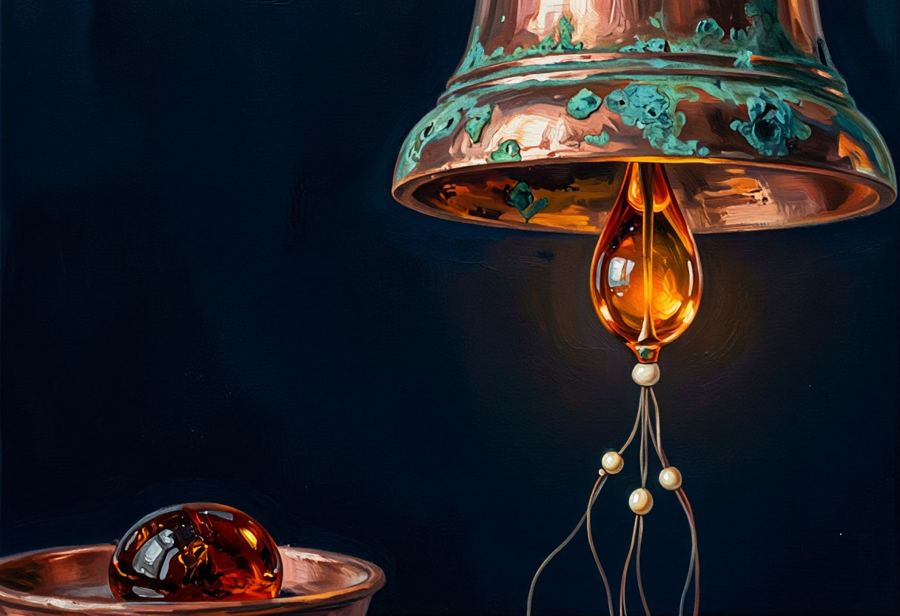

**Наблюдения VLM:** В верхней части изображения находится колокольчик, подвешенный вниз дном или позицией (отверстием). Внутренняя поверхность колокольчика сияет интенсивным янтарно-золотым светом, несмотря на то, что внешняя сторона покрыта сине-зеленым слоем окиси (патыны).; От дна колокольчика свисает капля вязкой, светящейся жидкости янтарного цвета, которая заменяет традиционный язычок или шнурок звона.; От капли отходят тонкие нити, на которых держатся три жемчужины разных размеров, формирующие подобие подвески или традиционного гонга.; В левом нижнем углу находится медная чаша или блюдо, в котором покоится капля похожей янтарной жидкости. На капле и в чаше заметны изящные блики.; Общий фон — глубокий, насыщенный темно-синий цвет (petrol blue), занимающий значительную часть кадра и создающий спокойную атмосферу.; Текстура играют маслом с видными мазками, имитирующими потерю материала на металле и матовость фарфора.; Отсутствуют какие-либо текстовые надписи, логотипы, экраны или элементы киберпанка.

**Замечания:** Визуальная идентичность колокольчика показана с искажением: его отливается на фоне глубокого фона, и внутреннее свечение выглядит почти динамичным, что нарушает каноны статической музейной картины и снижает общую 'тишину' (quiet atmosphere).; Диспропорции в размерах, жемчужные нити теряются на фоне, они не сглажены цветовым потенциалом.; Контраст текстур между звеньями нитей (несколько намеренно грубовато) и более гладкими объектами капитально конкурирует за внимание зрителя (отвлекает от динамики капли)

### Сад непрочитанных сообщений
Может ли невысказанное прорасти, если его так и не прочитали?

| Версия | Метафора | Композиция | Фактуры | Серия | Сумма | Выбор |
|:--|--:|--:|--:|--:|--:|:--|
| 1 | 4 | 4 | 5 | 5 | 18/20 | финал |
| 2 | 3 | 5 | 5 | 2 | 15/20 |  |

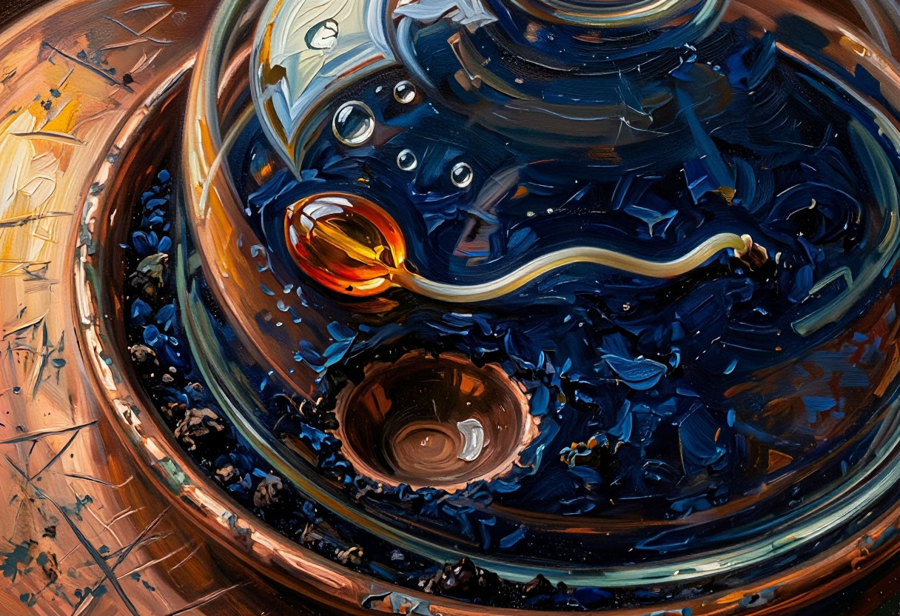

**Наблюдения VLM:** Холст заполнен абстрактной жидкой композицией с густой масляной фактурой (impasto).; Присутствуют глубокие, насыщенные синие тона, переходящие в темно-априсматический черновато-зеленые оттенки.; Один яркий акцентный объект — оранжево-янтарное «зерно» или капля с блестящей рефлексией света.; Текстура напоминает расплавленный металл (окисленная медь), темную воду и густую краску одновременно.; Отсутствуют какие-либо узнаваемые формы, тексты или техногенные элементы; это чистая абстрактная живопись.; Мягкое, рассеянное освещение подчеркивает рельеф штрихов, создавая объем без резких теней.

**Замечания:** Композиция немного перегружена по краям: левая часть с оранжево-коричневыми мазками и центральное «зерно» создают сильную конкуренцию за внимание, что размывает фокус.; Поскольку это деталь крупного плана (macroкосмос), видна недостаточная глубина пространства: кажется, что объекты находятся почти на одной плоскости.; Отсутствует пространство для дыхания (negative space): картина выглядит заполненной плотной массой без «воздуха», что снижает визуальную легкость, несмотря на тему «холста».

### Облачный гербарий
Что остаётся от обещания хранить воспоминания вечно?

| Версия | Метафора | Композиция | Фактуры | Серия | Сумма | Выбор |
|:--|--:|--:|--:|--:|--:|:--|
| 1 | 5 | 4 | 5 | 5 | 19/20 | финал |
| 2 | 3 | 4 | 5 | 3 | 15/20 |  |

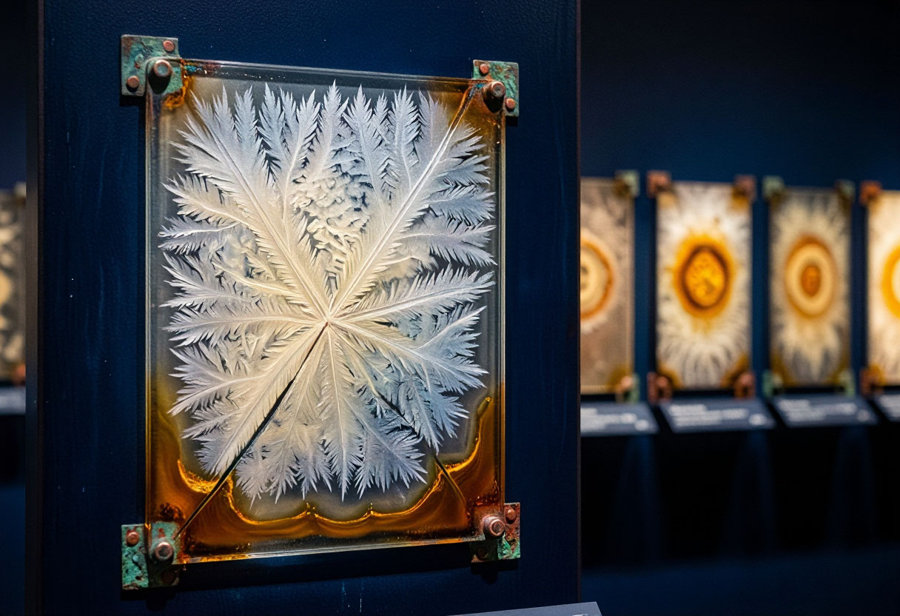

**Наблюдения VLM:** Центральная композиция: прямоугольный стеклянный рамка с заклепками по углам, внутри — сложный белый узор, напоминающийneedle или кристалл льда/снега.; Цветовое решение: фон глубокий синий, стекло имеет эффект янтарного/позолоченного стекла с темными краями.; Техника: детализация очень высокая, малейшее перо кристаллической структуры читаемо.; Освещение: объемный студийный свет с холодным голубым для формы и теплым золотым для люминесценции.; Фон: Нары в ряд случайной размытости (bokeh) на аналогичных стеклах, возможно имитируя ряд вечеров (clouds).

**Замечания:** Глаз инфантилен: центральная деталь передней рамки (рисунок) и самая яркая точка принтера абсолютно идентичны по форме и сложности.; Излишняя вложенность: вариации на |: Хотя общая декоративность хороша, они выглядят как вариации по заказу на тему Вы тоже не просто природа, а художественно идеализированная природа, это несколько утяжеляет 'тик-про' в концепции.

### Река отменённых маршрутов
Где живут места, до которых мы решили не дойти?

| Версия | Метафора | Композиция | Фактуры | Серия | Сумма | Выбор |
|:--|--:|--:|--:|--:|--:|:--|
| 1 | 4 | 3 | 5 | 4 | 16/20 |  |
| 2 | 4 | 5 | 4 | 5 | 18/20 | финал |

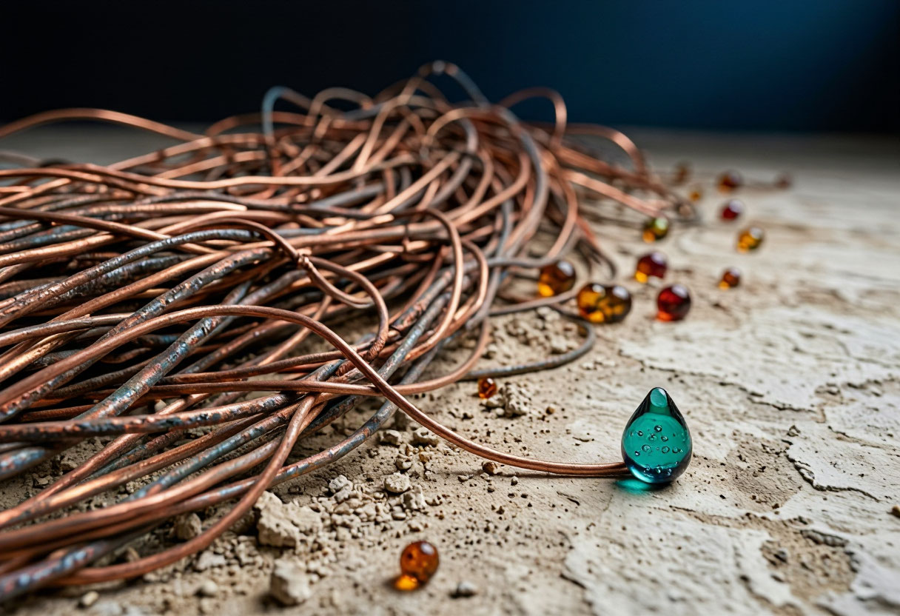

**Наблюдения VLM:** Крупный план кучи медных кабелей, лежащих на фоне текстурированной поверхности (похожей на бетон, алебастр или штукатурку).; Поверхность проводов местами покрыта патиной или грязью, что создает эффект старины.; От пучка проводов отходит один отдельный провод, который тянется вправо к одиночной капле.; Вторая капля больше, ярко-бирюзового (инеино-зеленого) цвета, по форме напоминает слезу или ледяной кристалл.; На плоскости разбросаны мелкие оранжевые полупрозрачные шарики (капли смолы или стекла), создающие эффект диагональной композиции.; Освещение теплое, падает сверху-слева, отбрасывая тени от проводов.; Глубина резкости использована: передний план каплей и часть кабеля в фокусе, остальная часть кабеля и фон уходят в размытие (боке).; Цветовая гамма: доминирует цвет меди и теплый бежевый землистый тон, акценты — холодный бирюзовый и янтарный.; Фактуры четкие: матовая шершавая основа, глянцевая гладкая капля и металлический блеск кабелей.

**Замечания:** Отсутствие истинно живописной (painterly) фактуры. Изображение очень 'цифровое' (photorealistic), кажутся недостатком для стиля 'fine-art paintings', который должен имитировать мазки или край краски.; Нарушение эталонов цвета: в промпте указан 'oxidised copper' (зеленая патина) в качестве основного страха медиа, но большая часть проводов цветная/чистая, а патина лишь на отдельных мелких участках.; Капля выглядит слишком 'милано-дизайнерски' (как бутылка парфюма или софтаматика), что немного выбивается из суровой атмосферы 'музея отмененных маршрутов' (хотя как 'потерянная слеза' концепт еще работает).

In [7]:
from IPython.display import Markdown, display

for work in manifest['works']:
    display(Markdown(f"### {work['title']}\n{work['brief']['question']}"))
    rows = ["| Версия | Метафора | Композиция | Фактуры | Серия | Сумма | Выбор |",
            "|:--|--:|--:|--:|--:|--:|:--|"]
    for candidate in work['candidates']:
        score = candidate['review']['scores']
        chosen = 'финал' if candidate['version'] == work['selected_version'] else ''
        rows.append(f"| {candidate['version']} | {score['metaphor']} | {score['composition']} | "
                    f"{score['materiality']} | {score['series_fit']} | {candidate['review']['total']}/20 | {chosen} |")
    display(Markdown('\n'.join(rows)))
    with Image.open(ASSETS / work['selected_image']) as picture:
        preview = picture.copy()
        preview.thumbnail((900, 900))
        display(preview)
    final = next(item for item in work['candidates'] if item['version'] == work['selected_version'])
    display(Markdown('**Наблюдения VLM:** ' + '; '.join(final['review']['observations'])))
    display(Markdown('**Замечания:** ' + '; '.join(final['review']['issues'])))


## Пример настоящего диалога

In [8]:
if manifest['works']:
    for event in manifest['works'][0]['dialogue']:
        display(Markdown(f"#### {event['role']} · {event['stage']}\nМодель: `{event['model']}`"))
        print(json.dumps(event.get('parsed'), ensure_ascii=False, indent=2))


#### curator · curator-concept
Модель: `deepseek-v4.1-flash`

{
  "concept": "Экспонат — колокол, отлитый из окисленной меди с зелёной коркой патины, того же сплава, что и вещи, которые когда-то звали людей. Языка у него нет: гнездо языка залито единственной каплей янтарного стекла, и эта капля светится сама, без источника. Край колокола запаян тонкой медной мембраной, чуть провисшей, как горло, держащее вдох: звук невозможен, полость держит свет. Подвешен колокол не на стержне — на пучке оборванных нитей, десятки волосков с крошечными узелками на концах, и каждый узелок висит там, где когда-то стоял слушатель. Композиция смещена: колокол уходит вправо и вверх, две трети холста — глубокий петроль стены и воздух. Единственный свет в картине — янтарная точка в гнезде и её отсвет, застрявший в ямках патины, как в порах кожи. Ниже, на ивори-полке, мелкая медная чаша, в ней застыла вторая капля: свет, который стекал столетиями и так и не был выпит. Никаких витрин, стекла и подписей — предмет висит в пустоте так, будто его только что сняли со стены и е

#### artist · artist-proposal
Модель: `qwen3.6-35b-a3b/latest`

null


#### artist · artist-proposal
Модель: `qwen3.6-35b-a3b/latest`

...

null


#### critic · critic-openweight
Модель: `qwen3.6-35b-a3b/latest`

null


#### critic · critic-openweight
Модель: `qwen3.6-35b-a3b/latest`

{
  "scores": {
    "metaphor": 3,
    "composition": 4,
    "series_fit": 3,
    "materiality": 5
  },
  "strengths": [
    "Отличный тактильный шарм: сильная материальность, скрипучая патина на меди и стеклоотражение дают полный визуальный тактильный опыт",
    "Мастерский свет: золотое свечение через зелёный купол отлично работает на «тёплый амбр свет» и мрачную атмосферу",
    "Выбрана правда — оформление продаёт ",
    "то"
  ],
  "observations": [
    "Центральное — купольный светильник, свисающий с ц проволочной трубой на серовато-сером фоне",
    "Купол покрыт густой зелёной патиной с точечными просветами охры; база — медная; абажур излучает янтарный свет снизу",
    "Отсутствуют фигуры, экраны, тексты, логотипы, неон; выдержана единая палитра (изумруд-медь-янтарь) и глубокий одноклассниковский студийный ракурс",
    "Фокус плотный; скрытый фон мягко размыт, давая пустое пространство",
    "Без прямых цифровых символов; образ читается как артефакт Вы, сконцентрированный на осве

## Открытая модель с Hugging Face

Модель: stabilityai/sd-turbo
Revision: b261bac6fd2cf515557d5d0707481eafa0485ec2
Seed: 2126 Шагов: 4 Разрешение: [512, 512] Устройство: mps


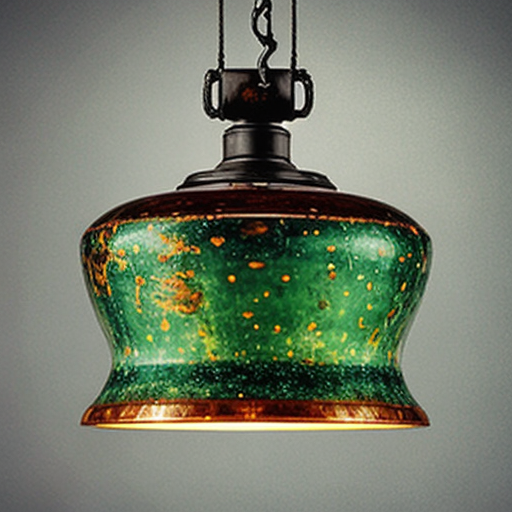

Субъективная оценка VLM: 15 / 20
Same submitted prompt; different resolution, tokenizer and compute. Not a controlled quality benchmark.


In [9]:
comparison = manifest.get('openweight')
if comparison:
    print('Модель:', comparison['model'])
    print('Revision:', comparison['revision'])
    print('Seed:', comparison['seed'], 'Шагов:', comparison['steps'],
          'Разрешение:', comparison['size'], 'Устройство:', comparison['device'])
    with Image.open(ASSETS / comparison['image']) as picture:
        display(picture.copy())
    if comparison.get('review'):
        print('Субъективная оценка VLM:', comparison['review']['total'], '/ 20')
    print(comparison['comparison_note'])
else:
    print('SD-Turbo ещё не запускалась; дополнительных результатов не заявляем.')


## Выводы и ограничения

Разделение ролей даёт наблюдаемый протокол принятия решений: сначала обсуждается
смысл, затем композиция, затем видимое изображение. Текстовая самокритика не
заменяет VLM: последняя обнаруживает несовпадения замысла с реальным рендером.

Контур обратной связи не гарантирует улучшения. Поэтому сохранение альтернатив,
проверяемое правило выбора и журнал важнее заявления «агенты улучшили всё».
Оценки одного VLM зависимы от его модели и промпта; художник и критик используют
одну базовую Qwen с разными ролями и контекстом. Независимый человеческий разбор
не проводился в рамках этого автоматизированного прогона.

SD-Turbo показывает возможность заменить рендерер открытыми весами. Сравнение
ограничено различием разрешений, длины текстового окна и вычислительного бюджета.
Для строгого исследования нужны несколько запусков, одинаковые условия и
слепое человеческое оценивание. Подробные фактические результаты — в REPORT.md.
